# Cvičenie I - Úvod a časové rady I

## 1. Načítanie datasetu a knižníc

Pracujeme s datasetom, v ktorom sú pozorovania zaznamenávané v pravidelných časových intervaloch, teda s rovnakým časovým odstupom.

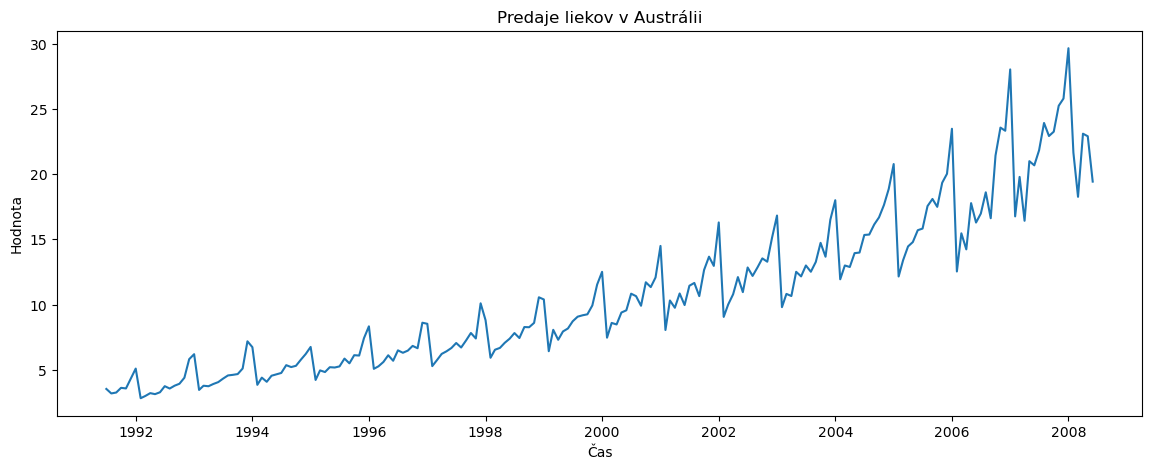

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data_a10 = pd.read_csv(
    "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv",
    parse_dates=["date"],
    index_col="date"
)

plt.figure(figsize=(14, 5))
plt.plot(data_a10)
plt.xlabel("Čas")
plt.ylabel("Hodnota")
plt.title("Predaje liekov v Austrálii")

plt.show()

### Akú frekvenciu má tento dataset?

Frekvencia určuje význam lagu aj sezónnej periódy.

In [8]:
# TODO: Použite funkciu z knižnice pandas na zistenie frekvencie datasetu.
data_a10.index.freq = pd.infer_freq(data_a10.index)
data_a10.index.freq

<MonthBegin>

## 2. Agregácia časového Radu

Agregáciou vieme sumarizovať a transformovať dáta cez špecifické intervaly: hodinová, denná, mesačná, kĺzavý priemer. 

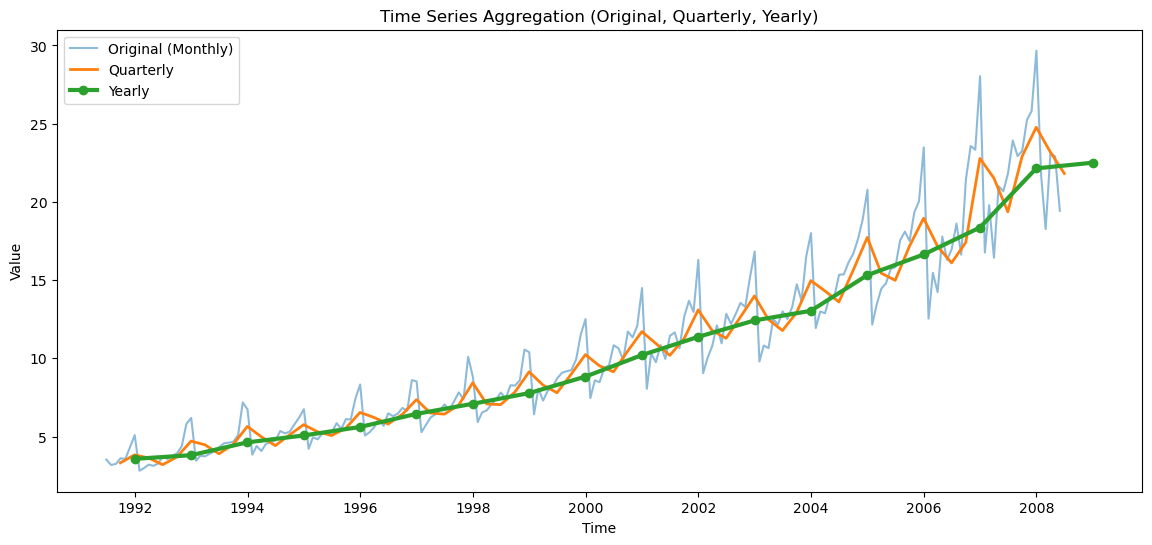

Variability (Standard Deviation):
Original data: 5.96
Quarterly data: 5.78
Yearly data: 6.09


In [13]:
# TODO: Vykreslite pôvodné dáta spolu s štvrťročne a ročne agregovanými. 
# Ako agregácia ovplyvnila extrémy a sezónne výkyvy? 
# TODO: Vypočítajte variabilitu pre všetky tri krivky

data_quarterly = data_a10.resample('QE').mean()
data_yearly = data_a10.resample('YE').mean()

plt.figure(figsize=(14, 6))
plt.plot(data_a10, label='Original (Monthly)', alpha=0.5)
plt.plot(data_quarterly, label='Quarterly', linewidth=2)
plt.plot(data_yearly, label='Yearly', linewidth=3, marker='o')

plt.xlabel("Time")
plt.ylabel("Value")
plt.title("Time Series Aggregation (Original, Quarterly, Yearly)")
plt.legend()
plt.show()

print("Variability (Standard Deviation):")
print(f"Original data: {data_a10.squeeze().std():.2f}")
print(f"Quarterly data: {data_quarterly.squeeze().std():.2f}")
print(f"Yearly data: {data_yearly.squeeze().std():.2f}")

## 3. Trend a sezónnosť

Trend pozorujeme vtedy, keď časový rad vykazuje dlhodobý rast alebo pokles. Sezónnosť pozorujeme vtedy, keď sa v časovom rade opakuje určitý vzor v pravidelných časových intervaloch. Časové rady môžu trend alebo sezónnosť, alebo oboje.

In [4]:
# TODO: Vykreslite nasledujúce datasety a určite či obsahuje trend, sezónnosť alebo obe zložky
'https://raw.githubusercontent.com/selva86/datasets/master/guinearice.csv'
'https://raw.githubusercontent.com/selva86/datasets/master/sunspotarea.csv'
'https://raw.githubusercontent.com/selva86/datasets/master/AirPassengers.csv'

'https://raw.githubusercontent.com/selva86/datasets/master/AirPassengers.csv'

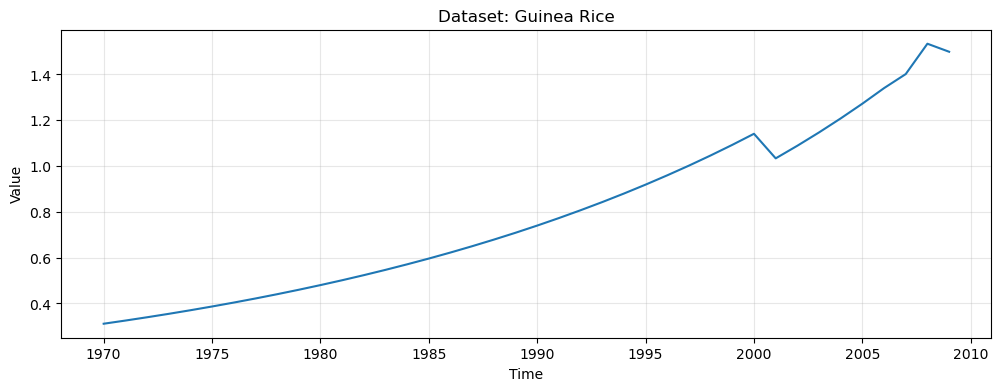

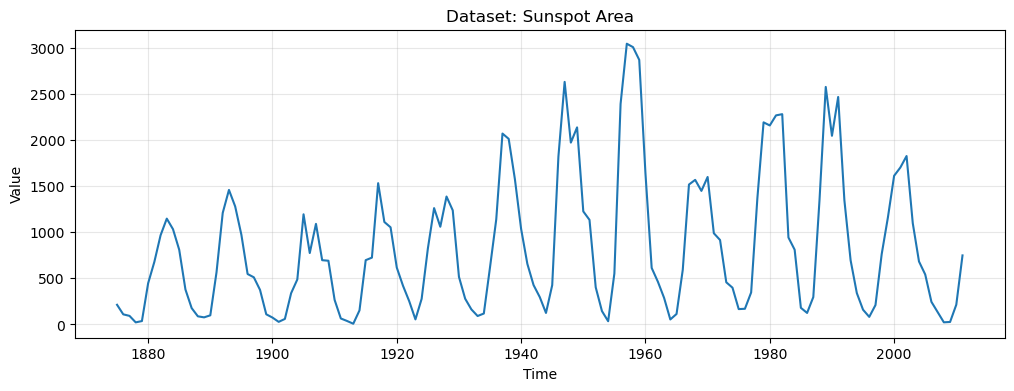

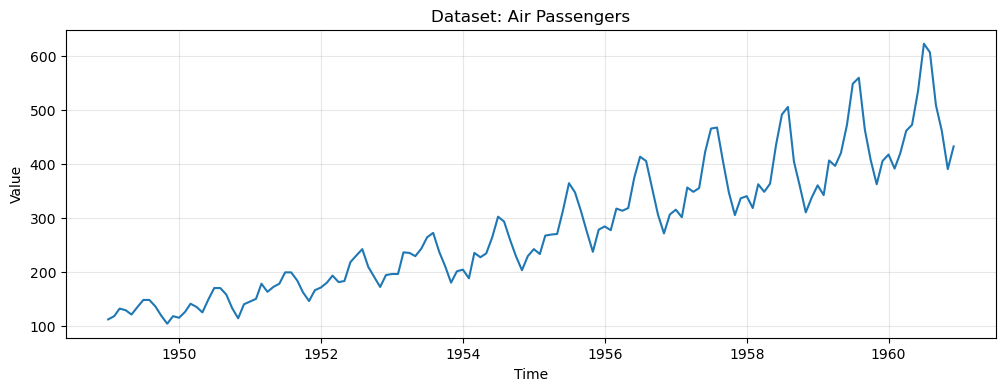

In [15]:
urls = {
    "Guinea Rice": "https://raw.githubusercontent.com/selva86/datasets/master/guinearice.csv",
    "Sunspot Area": "https://raw.githubusercontent.com/selva86/datasets/master/sunspotarea.csv",
    "Air Passengers": "https://raw.githubusercontent.com/selva86/datasets/master/AirPassengers.csv"
}

for name, url in urls.items():
    
    df = pd.read_csv(url, parse_dates=[0], index_col=0)
    
    plt.figure(figsize=(12, 4))
    plt.plot(df.squeeze())
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.title(f"Dataset: {name}")
    plt.grid(True, alpha=0.3)
    plt.show()

## 4. Aditívna a multiplikatívna sezónnosť

Závisiac od datasetu, dáta môžeme modelovať pomocou aditívneho a multiplikatívneho. modelu. Aditívna dekompozícia predpokladá, že sezónne výkyvy majú približne konštantnú absolútnu amplitúdu. Multiplikatívna dekompozícia sa používa, keď sezónne výkyvy rastú spolu s úrovňou dát. 

In [16]:
# TODO: Vykonajte aditívny a multiplikatívny model na datasete CO2 a datasete a10. 
# Porovnajte výsledky na grafe.

""" 
Graf by mal obsahovať 4 zložky: pozorovaný rad, trend, sezónnu zložku, rezídium.
Nezabudnite skontrolovať lag CO2 radu.
"""

import matplotlib.pyplot as plt
from statsmodels.datasets import co2
from statsmodels.tsa.seasonal import seasonal_decompose

In [6]:
# TODO: Vytvorte sezónny graf CO2 a a10. 
# Je amplitúda sezónnych výkyvov približne konštantná alebo rastie?

CO2 - Additive Decomposition:


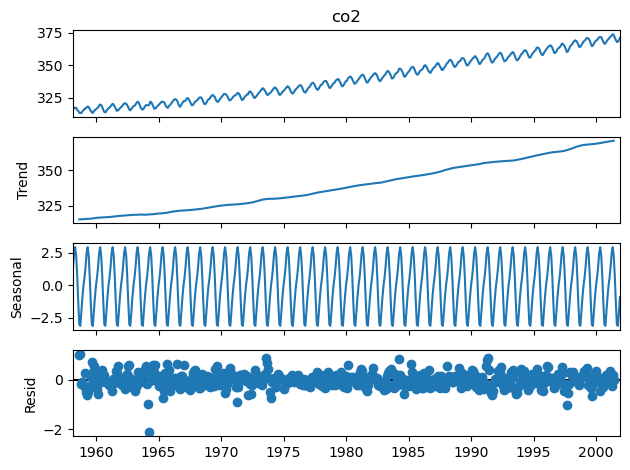

CO2 - Multiplicative Decomposition:


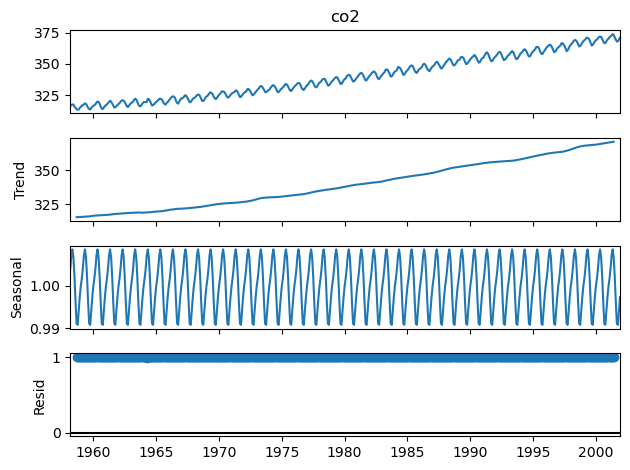

A10 - Additive Decomposition:


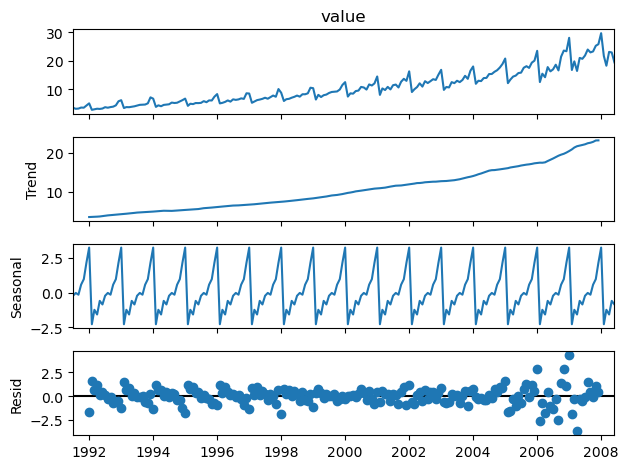

A10 - Multiplicative Decomposition:


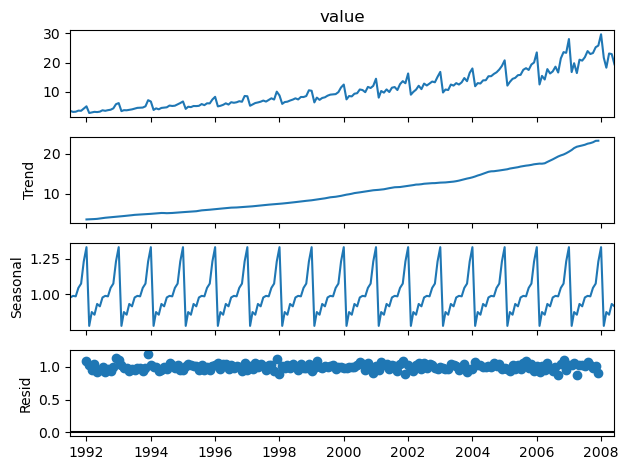

In [19]:
co2_data = co2.load_pandas().data

if 'date' in co2_data.columns:
    co2_data['date'] = pd.to_datetime(co2_data['date'])
    co2_data.set_index('date', inplace=True)
else:    
    co2_data.index = pd.to_datetime(co2_data.index)

co2_series = co2_data.iloc[:, 0].resample('MS').mean().ffill()

decomposition_co2_add = seasonal_decompose(co2_series, model='additive', period=12)
decomposition_co2_mul = seasonal_decompose(co2_series, model='multiplicative', period=12)

print("CO2 - Additive Decomposition:")
decomposition_co2_add.plot()
plt.show()

print("CO2 - Multiplicative Decomposition:")
decomposition_co2_mul.plot()
plt.show()

decomposition_a10_add = seasonal_decompose(data_a10.squeeze(), model='additive', period=12)
decomposition_a10_mul = seasonal_decompose(data_a10.squeeze(), model='multiplicative', period=12)

print("A10 - Additive Decomposition:")
decomposition_a10_add.plot()
plt.show()

print("A10 - Multiplicative Decomposition:")
decomposition_a10_mul.plot()
plt.show()

## 5. Stacionarita

 Stacionárny časový rad je taký, ktorého priemer, rozptyl a autokorelácia zostávajú v čase konštantné.
 Predikcie so stacionárnymi radmi sú spoľahlivejšie. 

 Diferencia je jeden zo spôsobov ako zmeniť nestacionárny rad na stacionárny. Ak Y_t je hodnota v čase t, tak prvá diferencia sa vypočíta ako Y_t - Y_t-1. Každá diferencia odoberá informáciu. 


In [7]:
# TODO: Vykreslite obyčajnú diferenciu, sezónnu diferenciu a kombináciu oboch na datasete a10. 
# Porovnajte výsledky na grafoch. Ktorá diferencia odstránila trend a ktorá sezónnosť?

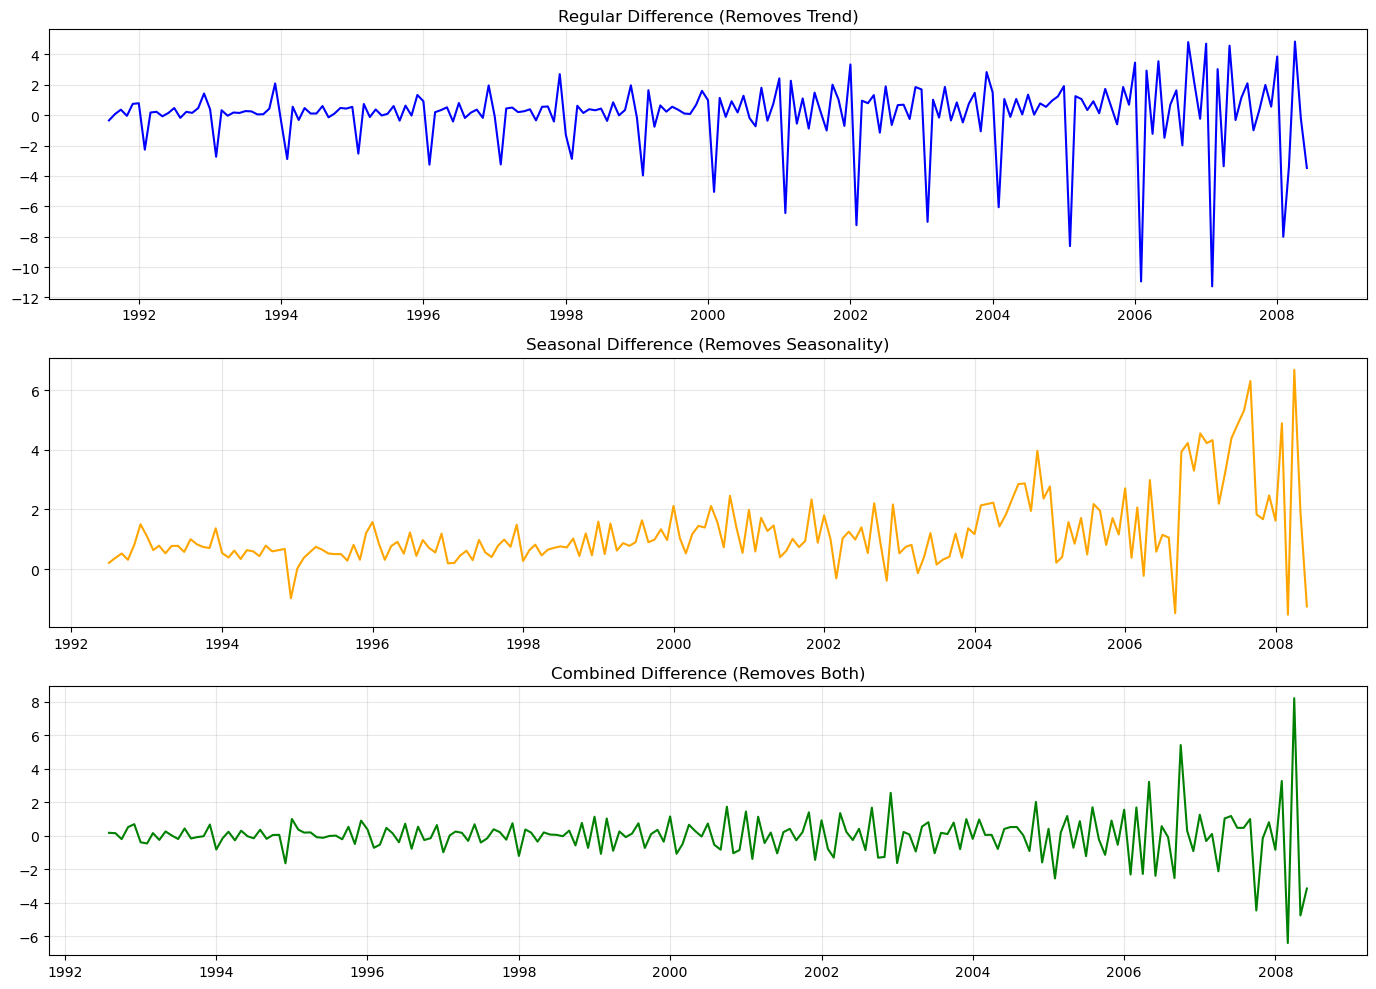

In [21]:
series_a10 = data_a10.squeeze()

diff_regular = series_a10.diff(1).dropna()

diff_seasonal = series_a10.diff(12).dropna()

diff_both = diff_seasonal.diff(1).dropna()

plt.figure(figsize=(14, 10))

plt.subplot(3, 1, 1)
plt.plot(diff_regular, color='blue')
plt.title("Regular Difference (Removes Trend)")
plt.grid(True, alpha=0.3)

plt.subplot(3, 1, 2)
plt.plot(diff_seasonal, color='orange')
plt.title("Seasonal Difference (Removes Seasonality)")
plt.grid(True, alpha=0.3)

plt.subplot(3, 1, 3)
plt.plot(diff_both, color='green')
plt.title("Combined Difference (Removes Both)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Testovanie stacionarity

Ak si nie sme istí vizuálnym odhadom, použijeme ADF (Augmented Dickey-Fuller) test alebo KPSS (Kwiatkowski-Phillips-Schmidt-Shin) test. 

ADF nulová hypotéza tvrdí, že časový rad obsahuje jednotkový koreň, a teda je nestacionárny. Ak je p hodnota menšia ako zvolená hladina významnosti, nulovú hypotézu zamietame a časový rad považujeme za stacionárny.

In [8]:
# TODO: Porovnajte stacionaritu a10 a CO2 datasetu pomocou ADF pred a po použití diferencie. 
# Kde je potrebné kombinovať obyčajnú aj sezónnu?

In [22]:
from statsmodels.tsa.stattools import adfuller

def run_adf_test(series, name):
    result = adfuller(series.dropna())
    print(f"--- ADF Test for {name} ---")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    if result[1] < 0.05:
        print("Result: Stationary (Reject H0)\n")
    else:
        print("Result: Non-stationary (Fail to reject H0)\n")

run_adf_test(data_a10.squeeze(), "a10 (Original)")
run_adf_test(co2_series, "CO2 (Original)")

a10_diff_both = data_a10.squeeze().diff(12).diff(1).dropna()
run_adf_test(a10_diff_both, "a10 (Seasonal + Regular Diff)")

co2_diff = co2_series.diff(1).dropna()
run_adf_test(co2_diff, "CO2 (Regular Diff)")

--- ADF Test for a10 (Original) ---
ADF Statistic: 3.1452
p-value: 1.0000
Result: Non-stationary (Fail to reject H0)

--- ADF Test for CO2 (Original) ---
ADF Statistic: 2.2848
p-value: 0.9989
Result: Non-stationary (Fail to reject H0)

--- ADF Test for a10 (Seasonal + Regular Diff) ---
ADF Statistic: -4.7834
p-value: 0.0001
Result: Stationary (Reject H0)

--- ADF Test for CO2 (Regular Diff) ---
ADF Statistic: -4.9239
p-value: 0.0000
Result: Stationary (Reject H0)



## 7. Autokorelácia

Autokorelácia meria lineárnu závislosť medzi hodnotami oddelenými lagom. 

Ak časový rad obsahuje trend, autokorelácia pri malých lagoch býva vysoká a kladná, pretože pozorovania, ktoré sú časovo blízke, majú zvyčajne aj podobné hodnoty. ACF časového radu s trendom preto často nadobúda kladné hodnoty, ktoré sa so zvyšujúcim oneskorením postupne znižujú.
Ak údaje obsahujú sezónnosť, vyššie hodnoty autokorelácie sa objavujú pri sezónnych lagoch. Napríklad pri mesačných údajoch s ročnou sezónnosťou môžeme očakávať vyššiu autokoreláciu pri lagoch 12, 24, 36 atď.
Ak časový rad obsahuje trend aj sezónnosť, v ACF môžeme pozorovať kombináciu oboch javov.

In [23]:
# TODO: Vykreslite ACF pôvodného radu a10 a ACF po vhodnej diferencii. 
# Pridajte do funkcie plot_acf parameter bartlett_confint=False pre vykreslenie fixného konfidenčného pásma.

from statsmodels.graphics.tsaplots import plot_acf

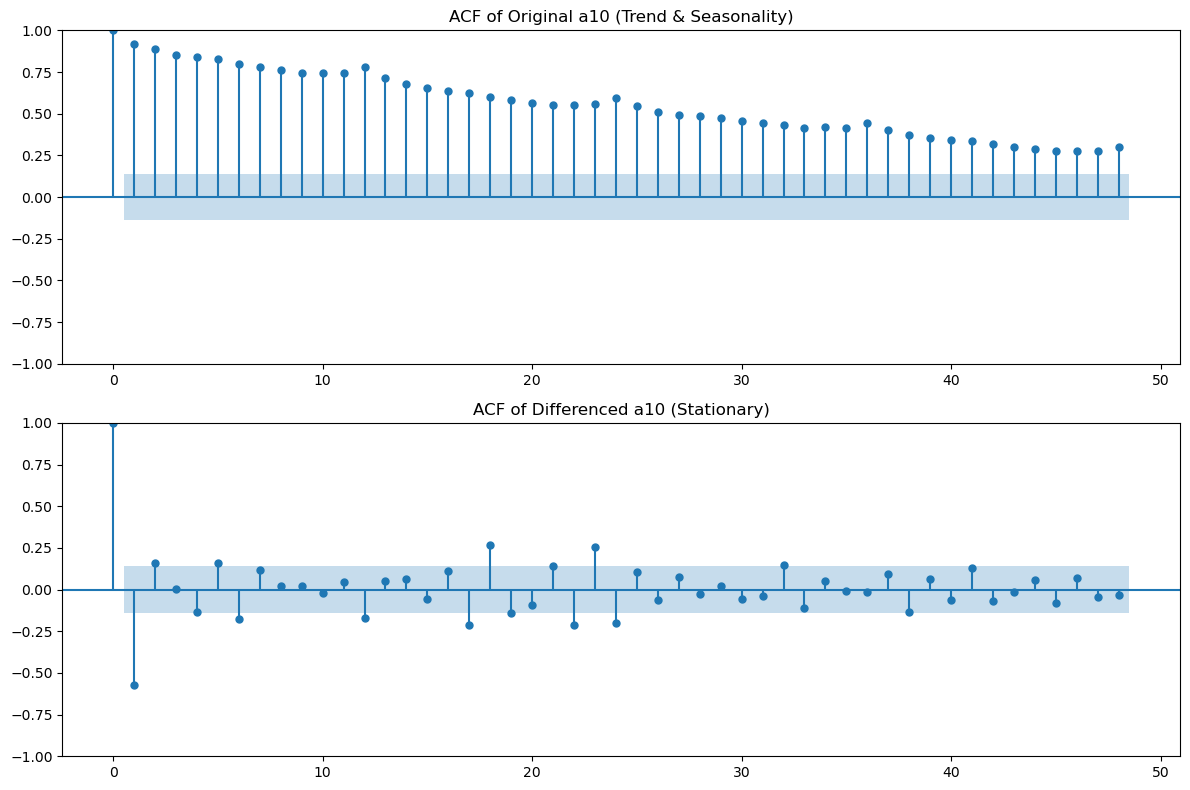

In [25]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(data_a10.squeeze(), ax=axes[0], lags=48, bartlett_confint=False)
axes[0].set_title("ACF of Original a10 (Trend & Seasonality)")

a10_diff = data_a10.squeeze().diff(12).diff(1).dropna()
plot_acf(a10_diff, ax=axes[1], lags=48, bartlett_confint=False)
axes[1].set_title("ACF of Differenced a10 (Stationary)")

plt.tight_layout()
plt.show()

## BONUS - 2 body

1. S datasetom a10 vykreslite 3 zložky časového radu pomocou STL (Seasonal and Trend decomposition using Loess). Keďže STL je aditívny, nezabudnite určiť, či dataset nepotrebuje logaritmickou transformáciu. Vyskúšajte STL bez logaritmickej transformácie. 

2. Aplikujte Box-Cox transformáciu. Aká je hodnota λ? Vysvetlite rozdiel medzi Box-Cox a diferenciou.

3. Otestujte dataset s KPSS testom. Vysvetli rozdiel medzi ADF a KPSS.


--- 1. STL Decomposition ---


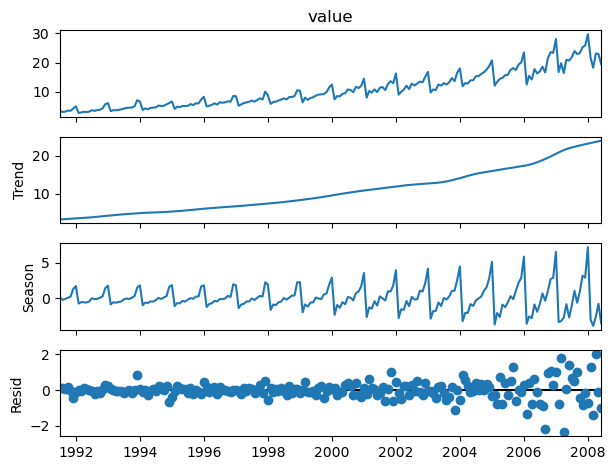

--- 2. Box-Cox Transformation ---
Optimal lambda (λ) value: 0.0615

--- 3. KPSS Test ---
KPSS Statistic: 2.0131
p-value: 0.0100
Result: Non-stationary (Reject H0)


In [28]:
import numpy as np
from statsmodels.tsa.seasonal import STL
from scipy.stats import boxcox
from statsmodels.tsa.stattools import kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter('ignore', InterpolationWarning)

series_a10 = data_a10.squeeze()

#1: STL
stl = STL(series_a10, period=12)
result_stl = stl.fit()

print("--- 1. STL Decomposition ---")
result_stl.plot()
plt.show()

#2: Box-Cox
transformed_series, lmbda = boxcox(series_a10)
print(f"--- 2. Box-Cox Transformation ---")
print(f"Optimal lambda (\u03bb) value: {lmbda:.4f}\n")

#3: KPSS 
kpss_result = kpss(series_a10.dropna(), regression='c', nlags='auto')
print(f"--- 3. KPSS Test ---")
print(f"KPSS Statistic: {kpss_result[0]:.4f}")
print(f"p-value: {kpss_result[1]:.4f}")
if kpss_result[1] < 0.05:
    print("Result: Non-stationary (Reject H0)")
else:
    print("Result: Stationary (Fail to reject H0)")